# CsI(Tl)–SiPM：连续RC与噪声分布联合校准

2026-10-30，承接[采集段条件响应](codex_0001_csi_state_response.ipynb)，按用户“继续”推进。
本轮细化RC并以完整PID协方差、核心IQR、波形起伏均值与事件间起伏共同约束噪声。
**全部实验已经探索，本轮是条件校准与内部检查，没有新增独立实验或Geant4输运母事件。**


In [1]:
from pathlib import Path
import json,sys
import numpy as np
from IPython.display import display,Markdown,Image
PROJECT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'simulation/main.cc').exists())
OUT=PROJECT/'simulation/results/rc_refinement_20261030'
def read(p):return json.loads(Path(p).read_text())
def table(headers,rows):
    return '\n'.join(['|'+'|'.join(headers)+'|','|'+'|'.join(['---']*len(headers))+'|']+['|'+'|'.join(map(str,r))+'|' for r in rows])
def f(x,n=3):return '不可估计' if x is None else f'{x:.{n}f}'
def nums(x):return ' / '.join(f(v) for v in x)
def ci(r):return '不可估计' if r['CI95'] is None else '['+', '.join(f(v) for v in r['CI95'])+']'
p=read(OUT/'protocol.json');cal=read(OUT/'mean_calibration.json');select=read(OUT/'noise_selection.json')
e=read(OUT/'evaluation.json');decision=read(OUT/'decision.json');cache=read(OUT/'cache_verification.json')
variants=e['variants'];labels=['原冻结参数','粗RC+扩展谱','连续RC/继承噪声','连续RC+原谱/原CV','连续RC+原谱/拟合CV','连续RC+扩展谱/原CV','连续RC+扩展谱/拟合CV']
display(Markdown(decision['conclusion_zh']))
print('新研究用原生任务/事件条目:',decision['native_jobs'],decision['native_replay_entries'])
print('不同原母事件470，支持Q箱内456；新增独立母事件0。')
print('缓存工程核验:',cache['paired_event_cases'],'个逐点相同的配对事件对照。')
print('Python / NumPy:',sys.version.split()[0],np.__version__)

新研究用原生任务/事件条目: 490 115150
不同原母事件470，支持Q箱内456；新增独立母事件0。
缓存工程核验: 216 个逐点相同的配对事件对照。
Python / NumPy: 3.13.5 2.5.4


本轮完成连续RC、原生含噪声响应校正和噪声分布联合约束。Am晚段扩展谱方案（块128）的MC−实测平均时间差由上一轮1.41 ns变为0.68 ns；时间IQR比为0.981，QDC/PCA IQR比为1.160/1.148，绝对平均ADC波形NRMSE为1.40%。主要进展是时间中心对分块的敏感性减小；三个PID的联合分布仍未全面吻合，不能称为已解决带宽差异。

## 1. 固定数据和划分

run3为⁶⁰Co源、run12为²⁴¹Am源；Am同时有α、γ和衰变电子，实验主带不作为粒子真值。
保留原ID、原Q、冻结PCA及first60箱内Q两分目标，Co支持6个Q箱，Am支持前3箱。470条固定MC波形来自原8000/24000个输运母事件，支持区内为276/180条。
每个first60/middle20/last20段按`(原事件ID // 块长) % 2`分两折，对折拟合、本折检查；块128为主，64为敏感性分析。MC沿用上一轮母事件折分，每母事件每组比较只选一套响应。

前触发状态拟合继承上一轮。既有光学参数、PCA和Q目标仍共享先前校准信息；交叉划分只隔离新增拟合层，不是全流程独立验证。
本轮C++从保存的Geant4雪崩历史重算读出，几何、光学、传感器物理冻结；完整输运入口和`include/`、`src/`类结构保留。


In [2]:
rows=[]
for key,g in p['groups'].items():
    fs=g['folds']['128'];rows.append([key,len(g['ids']),len(fs['0']['calibration_ids']),len(fs['0']['evaluation_ids']),g['span']])
display(Markdown(table(['组','原主带数','评价折0训练数','评价折0检查数','原事件区间'],rows)))
print('原Q箱边界:',p['q_edges'])

原Q箱边界: [201824.1125, 237975.62708333333, 274127.14166666666, 310278.65625, 346430.17083333334, 382581.6854166667, 418733.2]


|组|原主带数|评价折0训练数|评价折0检查数|原事件区间|
|---|---|---|---|---|
|run3_first60|2423|1207|1216|[0, 2865]|
|run3_middle20|843|434|409|[2865, 3820]|
|run3_last20|821|395|426|[3820, 4776]|
|run12_first60|1547|762|785|[0, 4509]|
|run12_middle20|460|220|240|[4509, 6012]|
|run12_last20|407|214|193|[6012, 7516]|

## 2. 连续RC与含噪声定位

范围保持96–160 ns：原生无噪声网格步长2 ns，再加入原128.21494566 ns点；复用10项旧输出，新算58项。
只对汇总的76个40 ns绝对ADC门均值、平均时间、短/长积分比及2–3 μs尾部比例作PCHIP插值。0.25 ns全范围搜索后局部有界优化，全局传输系数限于0.45–0.55；目标尺度沿用上一轮。
**插值仅提出参数，实际比较的每条ADC都由C++在新RC下生成。** 无逐事件缩放或实测模板注入。

随后执行两轮预设的原生含噪声偏差校正：用当前含噪声汇总响应减去无噪声预测，局部校正提案，再在原范围拟合。按训练均值目标选第0/1/2轮最低损失者。
多项均值约束可能互相权衡，不按时间中心一项挑最优。128次训练块重拟合固定原生偏差和其它参数，仅报告条件稳定性。


|条件/评价折|RC/ns|传输|迭代|RC条件重拟合2.5/50/97.5%|有效次数|
|---|---|---|---|---|---|
|run3_first60_B128_eval0|130.533|0.50112|2|129.223 / 130.562 / 132.046|128|
|run3_first60_B128_eval1|130.034|0.50040|2|129.003 / 130.001 / 131.045|128|
|run3_middle20_B128_eval0|131.946|0.50107|2|130.653 / 131.906 / 132.938|127|
|run3_middle20_B128_eval1|132.351|0.50202|1|129.759 / 132.431 / 135.208|110|
|run3_last20_B128_eval0|130.317|0.50084|2|129.174 / 130.317 / 132.116|127|
|run3_last20_B128_eval1|130.571|0.50084|2|129.628 / 130.500 / 131.039|104|
|run12_first60_B128_eval0|122.598|0.49808|2|119.292 / 122.520 / 125.947|128|
|run12_first60_B128_eval1|125.144|0.49802|1|122.600 / 125.235 / 128.367|128|
|run12_middle20_B128_eval0|124.785|0.49759|2|119.715 / 125.754 / 133.592|128|
|run12_middle20_B128_eval1|122.368|0.49773|2|117.523 / 122.124 / 128.526|128|
|run12_last20_B128_eval0|121.935|0.49904|2|113.764 / 122.121 / 128.380|128|
|run12_last20_B128_eval1|115.963|0.49935|2|111.143 / 115.482 / 123.865|128|

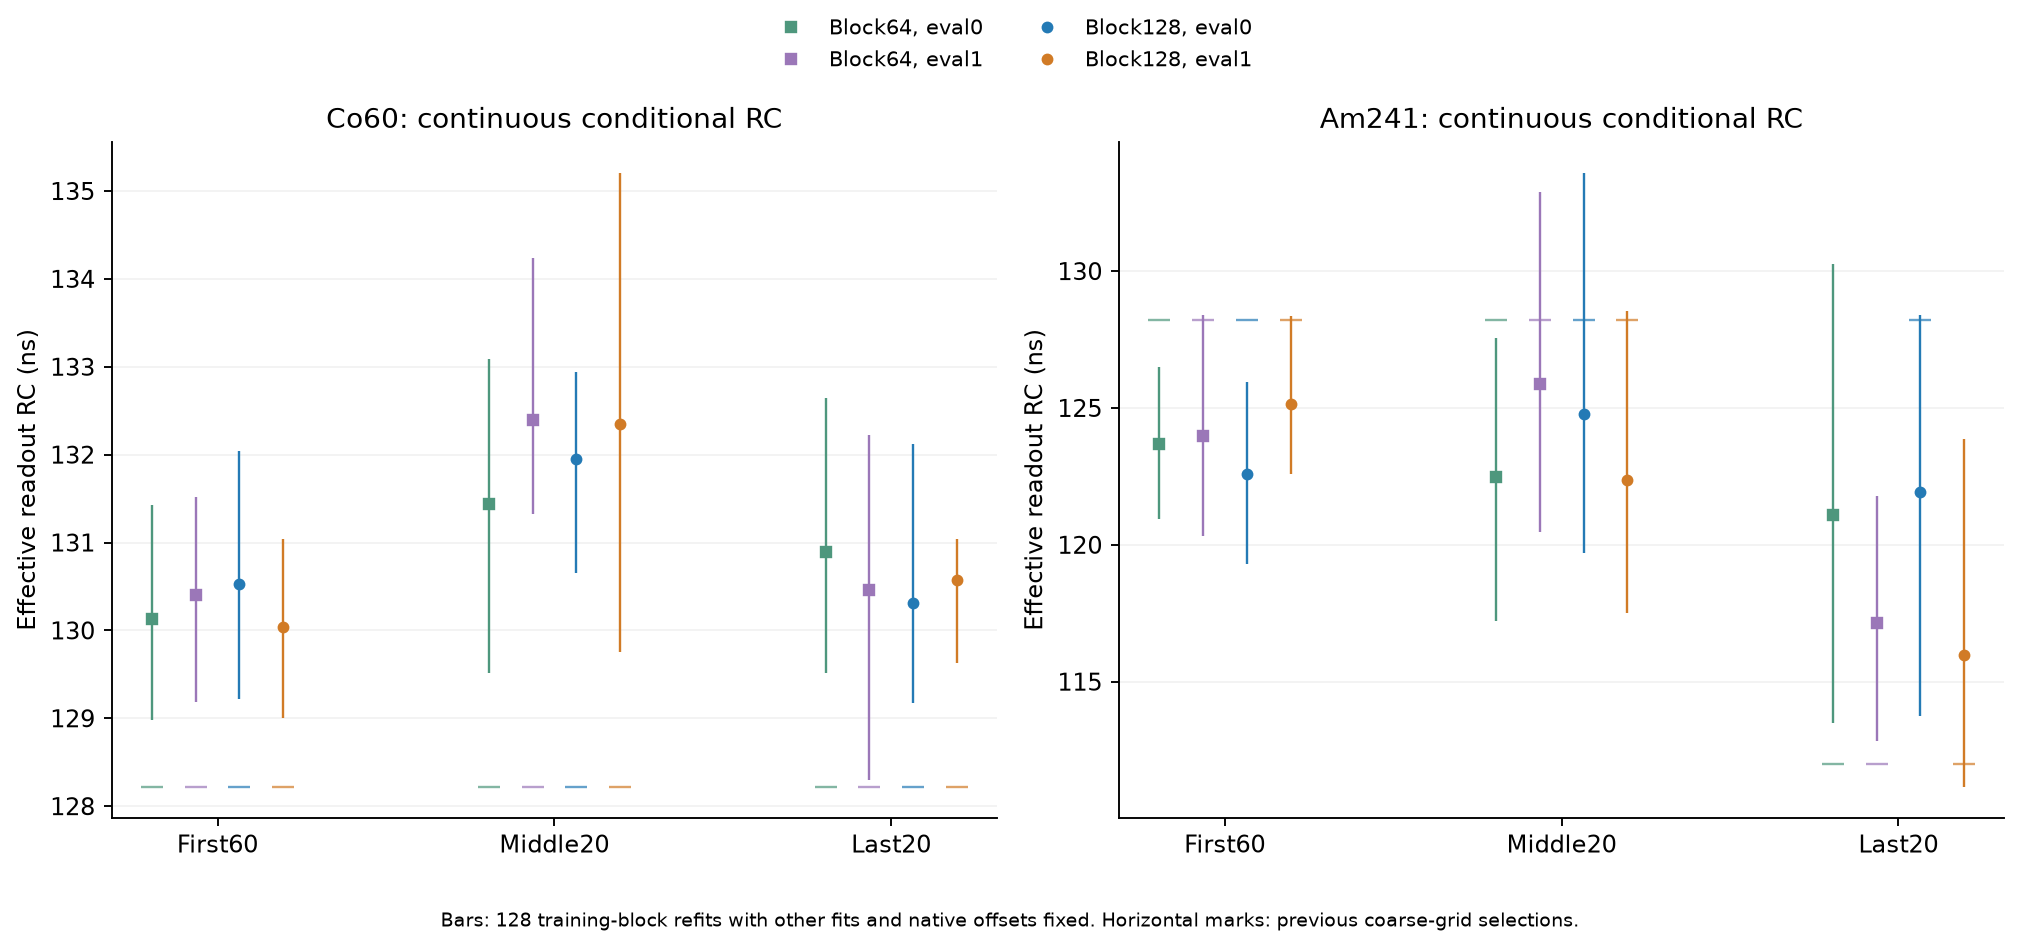

In [3]:
rows=[]
for key,r in cal['groups'].items():
    if r['entry']['block']!=128:continue
    z=read(PROJECT/r['fit']);b=np.array(z['training_block_refits'])
    rows.append([key,f(r['RC_ns']),f(r['transmission'],5),r['selected_round'],nums(np.quantile(b[:,0],[.025,.5,.975])),len(b)])
display(Markdown(table(['条件/评价折','RC/ns','传输','迭代','RC条件重拟合2.5/50/97.5%','有效次数'],rows)))
display(Image(filename=str(OUT/'figures/continuous_RC_calibration.png')))

这些是有效响应参数，不能当作实测电阻/电容或温度。连续RC和原生定位校正共同构成新流程，与上一轮的变化不能全部归于单一原因。

## 3. 噪声协方差、核心和尾部

先保留原谱、原谱+400/1500 ns指数核两个正功率谱族，以完整3×3箱内PID协方差和F50/F102/F202均值拟合非负功率。
F是盒滤波残差在信号区[500,2500) ns的方差减去前触发[−600,−200) ns方差，除以信号均值；相对实际分数t₁₀，定义及整数边界沿用上一轮。

再扫描事件方差乘子的CV：原值和0、0.25、0.5、1、1.5、2。乘子服从均值1的对数正态分布，噪声RMS乘其平方根；改变的是有效残差分布，不是光产额、SiPM增益或逐事件信号幅度。
各谱族只用训练块选CV。损失同时包含原均值目标、完整PID协方差、三项F均值、三种PID的IQR、三项F的箱内标准差；尺度事先固定。协方差约束总方差，IQR约束核心，F标准差限制极端噪声状态。
全部CV候选与原CV对照保留。128次CV选择重采样固定RC、功率、谱、电子学和MC；功率重拟合另存，均不是完整嵌套不确定度。


|条件/评价折|谱族|原CV|选择CV|CV序列|条件重选计数|
|---|---|---|---|---|---|
|run3_first60_B128_eval0|inherited|0.199|0.199|0.00 / 0.20 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|1 / 127 / 0 / 0 / 0 / 0 / 0|
|run3_first60_B128_eval0|spectrum|0.199|0.199|0.00 / 0.20 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|1 / 127 / 0 / 0 / 0 / 0 / 0|
|run3_first60_B128_eval1|inherited|0.199|0.199|0.00 / 0.20 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|8 / 120 / 0 / 0 / 0 / 0 / 0|
|run3_first60_B128_eval1|spectrum|0.199|0.199|0.00 / 0.20 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|16 / 112 / 0 / 0 / 0 / 0 / 0|
|run3_middle20_B128_eval0|inherited|0.199|0.199|0.00 / 0.20 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|1 / 94 / 33 / 0 / 0 / 0 / 0|
|run3_middle20_B128_eval0|spectrum|0.199|0.199|0.00 / 0.20 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|0 / 114 / 14 / 0 / 0 / 0 / 0|
|run3_middle20_B128_eval1|inherited|0.199|0.199|0.00 / 0.20 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|27 / 73 / 0 / 0 / 0 / 0 / 0|
|run3_middle20_B128_eval1|spectrum|0.199|0.199|0.00 / 0.20 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|22 / 78 / 0 / 0 / 0 / 0 / 0|
|run3_last20_B128_eval0|inherited|0.199|0.199|0.00 / 0.20 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|14 / 110 / 0 / 0 / 0 / 0 / 0|
|run3_last20_B128_eval0|spectrum|0.199|0.199|0.00 / 0.20 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|11 / 113 / 0 / 0 / 0 / 0 / 0|
|run3_last20_B128_eval1|inherited|0.199|0.199|0.00 / 0.20 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|9 / 96 / 0 / 0 / 0 / 0 / 0|
|run3_last20_B128_eval1|spectrum|0.199|0.199|0.00 / 0.20 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|9 / 96 / 0 / 0 / 0 / 0 / 0|
|run12_first60_B128_eval0|inherited|0.090|0.000|0.00 / 0.09 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|127 / 1 / 0 / 0 / 0 / 0 / 0|
|run12_first60_B128_eval0|spectrum|0.090|0.000|0.00 / 0.09 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|112 / 16 / 0 / 0 / 0 / 0 / 0|
|run12_first60_B128_eval1|inherited|0.090|0.000|0.00 / 0.09 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|128 / 0 / 0 / 0 / 0 / 0 / 0|
|run12_first60_B128_eval1|spectrum|0.090|0.000|0.00 / 0.09 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|128 / 0 / 0 / 0 / 0 / 0 / 0|
|run12_middle20_B128_eval0|inherited|0.090|0.000|0.00 / 0.09 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|128 / 0 / 0 / 0 / 0 / 0 / 0|
|run12_middle20_B128_eval0|spectrum|0.090|0.000|0.00 / 0.09 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|128 / 0 / 0 / 0 / 0 / 0 / 0|
|run12_middle20_B128_eval1|inherited|0.090|0.000|0.00 / 0.09 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|125 / 3 / 0 / 0 / 0 / 0 / 0|
|run12_middle20_B128_eval1|spectrum|0.090|0.000|0.00 / 0.09 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|126 / 2 / 0 / 0 / 0 / 0 / 0|
|run12_last20_B128_eval0|inherited|0.090|0.000|0.00 / 0.09 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|127 / 0 / 0 / 0 / 0 / 0 / 0|
|run12_last20_B128_eval0|spectrum|0.090|0.000|0.00 / 0.09 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|127 / 0 / 0 / 0 / 0 / 0 / 0|
|run12_last20_B128_eval1|inherited|0.090|0.090|0.00 / 0.09 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|40 / 88 / 0 / 0 / 0 / 0 / 0|
|run12_last20_B128_eval1|spectrum|0.090|0.090|0.00 / 0.09 / 0.25 / 0.50 / 1.00 / 1.50 / 2.00|34 / 94 / 0 / 0 / 0 / 0 / 0|

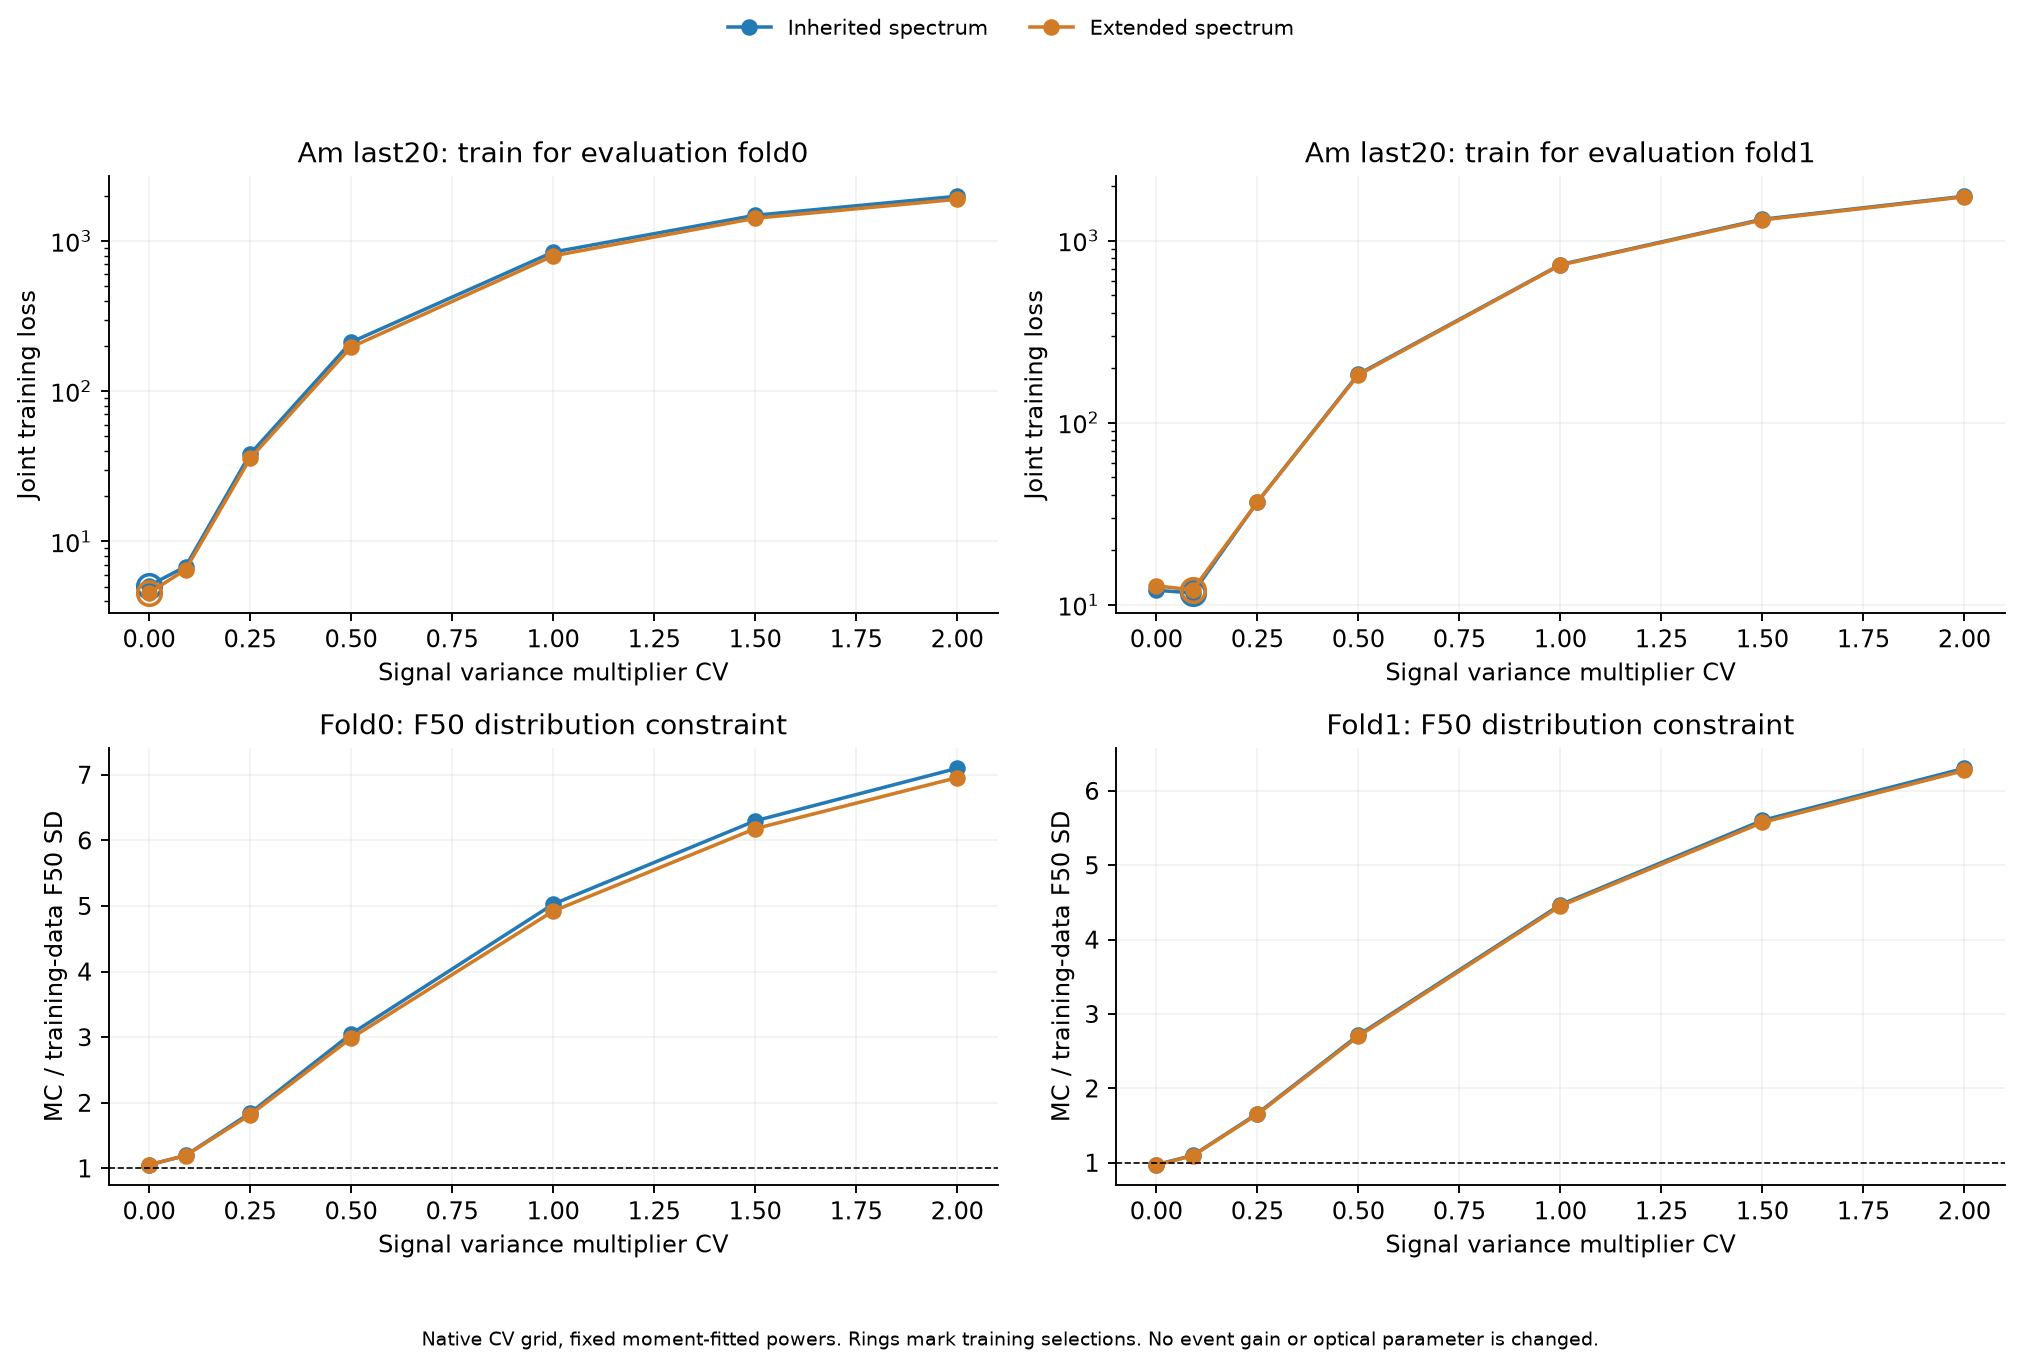

In [4]:
rows=[]
for key,r in select['groups'].items():
    if '_B128_' not in key:continue
    fit=read(PROJECT/r['fit'])
    for family,z in fit['families'].items():
        counts=np.bincount(z['conditional_selection_refits'],minlength=len(z['choices']))
        rows.append([key,family,f(z['inherited_CV']),f(z['chosen_CV']),' / '.join(f(v['CV'],2) for v in z['choices']),' / '.join(map(str,counts))])
display(Markdown(table(['条件/评价折','谱族','原CV','选择CV','CV序列','条件重选计数'],rows)))
display(Image(filename=str(OUT/'figures/variance_scatter_selection.png')))

新增`replay_readout_cached`复用最近一套原生基础响应，每个残差候选仍按原事件种子生成。读出/电子学/相位/窗口变化时缓存失效。
缓存只优化计算：216个配对事件覆盖CV、谱形、关闭残差、RC、相位和电子学变化，ADC/无噪声信号/模拟电压与旧程序逐值相同；普通重放入口也完成编译。未新增物理近似。

## 4. 原生联合检查

时间差为MC−实测；IQR/SD/F比值为MC/实测。NRMSE为76个绝对ADC均值的L₂残差除以实测均值L₂范数。
512次完整原母事件和原始实验事件块配对重采样，固定拟合、CV选择、Q目标、PCA及折分。区间是固定拟合的条件区间，未包含完整模型选择误差，也未作等效性检验。
不按新的Q、波形形状或结果重新筛选事件。每条新ADC仍按原定义重新计算基线与t₁₀锚点，使用原Q只做固定目标匹配；比值接近1和区间覆盖1都不等于证明一致。


|组|模型|时间差/ns|QDC/时间/PCA IQR比|QDC/时间/PCA SD比|ADC NRMSE|
|---|---|---|---|---|---|
|run3_first60|原冻结参数|-0.103|0.918 / 0.934 / 1.026|0.981 / 0.960 / 1.002|3.21%|
|run3_first60|粗RC+扩展谱|-0.089|0.957 / 0.941 / 1.052|1.014 / 0.994 / 1.034|3.22%|
|run3_first60|连续RC/继承噪声|1.653|0.917 / 0.938 / 1.021|0.980 / 0.960 / 1.000|3.02%|
|run3_first60|连续RC+原谱/拟合CV|1.647|0.922 / 0.938 / 1.026|0.982 / 0.962 / 1.002|3.02%|
|run3_first60|连续RC+扩展谱/拟合CV|1.670|0.955 / 0.946 / 1.059|1.017 / 0.996 / 1.036|3.02%|
|run3_middle20|原冻结参数|-1.838|1.032 / 1.075 / 1.192|1.015 / 1.013 / 1.067|3.23%|
|run3_middle20|粗RC+扩展谱|-1.803|1.043 / 1.060 / 1.190|1.010 / 0.995 / 1.057|3.23%|
|run3_middle20|连续RC/继承噪声|1.566|1.038 / 1.090 / 1.205|1.009 / 1.010 / 1.059|2.91%|
|run3_middle20|连续RC+原谱/拟合CV|1.565|1.037 / 1.091 / 1.203|1.008 / 1.008 / 1.058|2.91%|
|run3_middle20|连续RC+扩展谱/拟合CV|1.578|1.055 / 1.078 / 1.194|1.005 / 0.995 / 1.052|2.91%|
|run3_last20|原冻结参数|-0.498|0.997 / 0.940 / 1.015|0.951 / 0.987 / 0.971|3.17%|
|run3_last20|粗RC+扩展谱|-0.436|1.029 / 0.966 / 1.038|0.974 / 1.010 / 0.992|3.18%|
|run3_last20|连续RC/继承噪声|1.423|0.993 / 0.934 / 1.017|0.949 / 0.986 / 0.968|2.96%|
|run3_last20|连续RC+原谱/拟合CV|1.428|0.987 / 0.933 / 1.015|0.947 / 0.983 / 0.966|2.96%|
|run3_last20|连续RC+扩展谱/拟合CV|1.415|1.060 / 0.956 / 1.037|0.974 / 1.008 / 0.991|2.96%|
|run12_first60|原冻结参数|2.241|1.156 / 1.076 / 1.219|1.022 / 0.967 / 1.040|1.72%|
|run12_first60|粗RC+扩展谱|2.188|1.152 / 1.076 / 1.223|1.022 / 0.963 / 1.039|1.71%|
|run12_first60|连续RC/继承噪声|-0.717|1.171 / 1.071 / 1.191|1.027 / 0.971 / 1.046|1.37%|
|run12_first60|连续RC+原谱/拟合CV|-1.001|1.148 / 1.083 / 1.211|1.026 / 0.970 / 1.048|1.37%|
|run12_first60|连续RC+扩展谱/拟合CV|-1.005|1.147 / 1.082 / 1.206|1.026 / 0.965 / 1.046|1.37%|
|run12_middle20|原冻结参数|1.543|1.208 / 0.900 / 1.262|1.004 / 0.846 / 1.011|1.77%|
|run12_middle20|粗RC+扩展谱|1.817|1.275 / 0.945 / 1.201|1.041 / 0.899 / 1.058|1.73%|
|run12_middle20|连续RC/继承噪声|-1.622|1.241 / 0.934 / 1.243|1.032 / 0.871 / 1.043|1.31%|
|run12_middle20|连续RC+原谱/拟合CV|-1.815|1.213 / 0.930 / 1.216|1.028 / 0.868 / 1.042|1.32%|
|run12_middle20|连续RC+扩展谱/拟合CV|-1.684|1.234 / 0.943 / 1.253|1.058 / 0.904 / 1.075|1.33%|
|run12_last20|原冻结参数|7.258|1.058 / 0.917 / 1.096|0.978 / 0.829 / 0.962|1.97%|
|run12_last20|粗RC+扩展谱|1.407|1.134 / 0.978 / 1.174|1.097 / 0.924 / 1.089|1.36%|
|run12_last20|连续RC/继承噪声|0.945|1.125 / 0.965 / 1.096|1.027 / 0.876 / 1.018|1.39%|
|run12_last20|连续RC+原谱/拟合CV|0.795|1.120 / 0.942 / 1.087|1.019 / 0.869 / 1.011|1.40%|
|run12_last20|连续RC+扩展谱/拟合CV|0.678|1.160 / 0.981 / 1.148|1.065 / 0.923 / 1.060|1.40%|

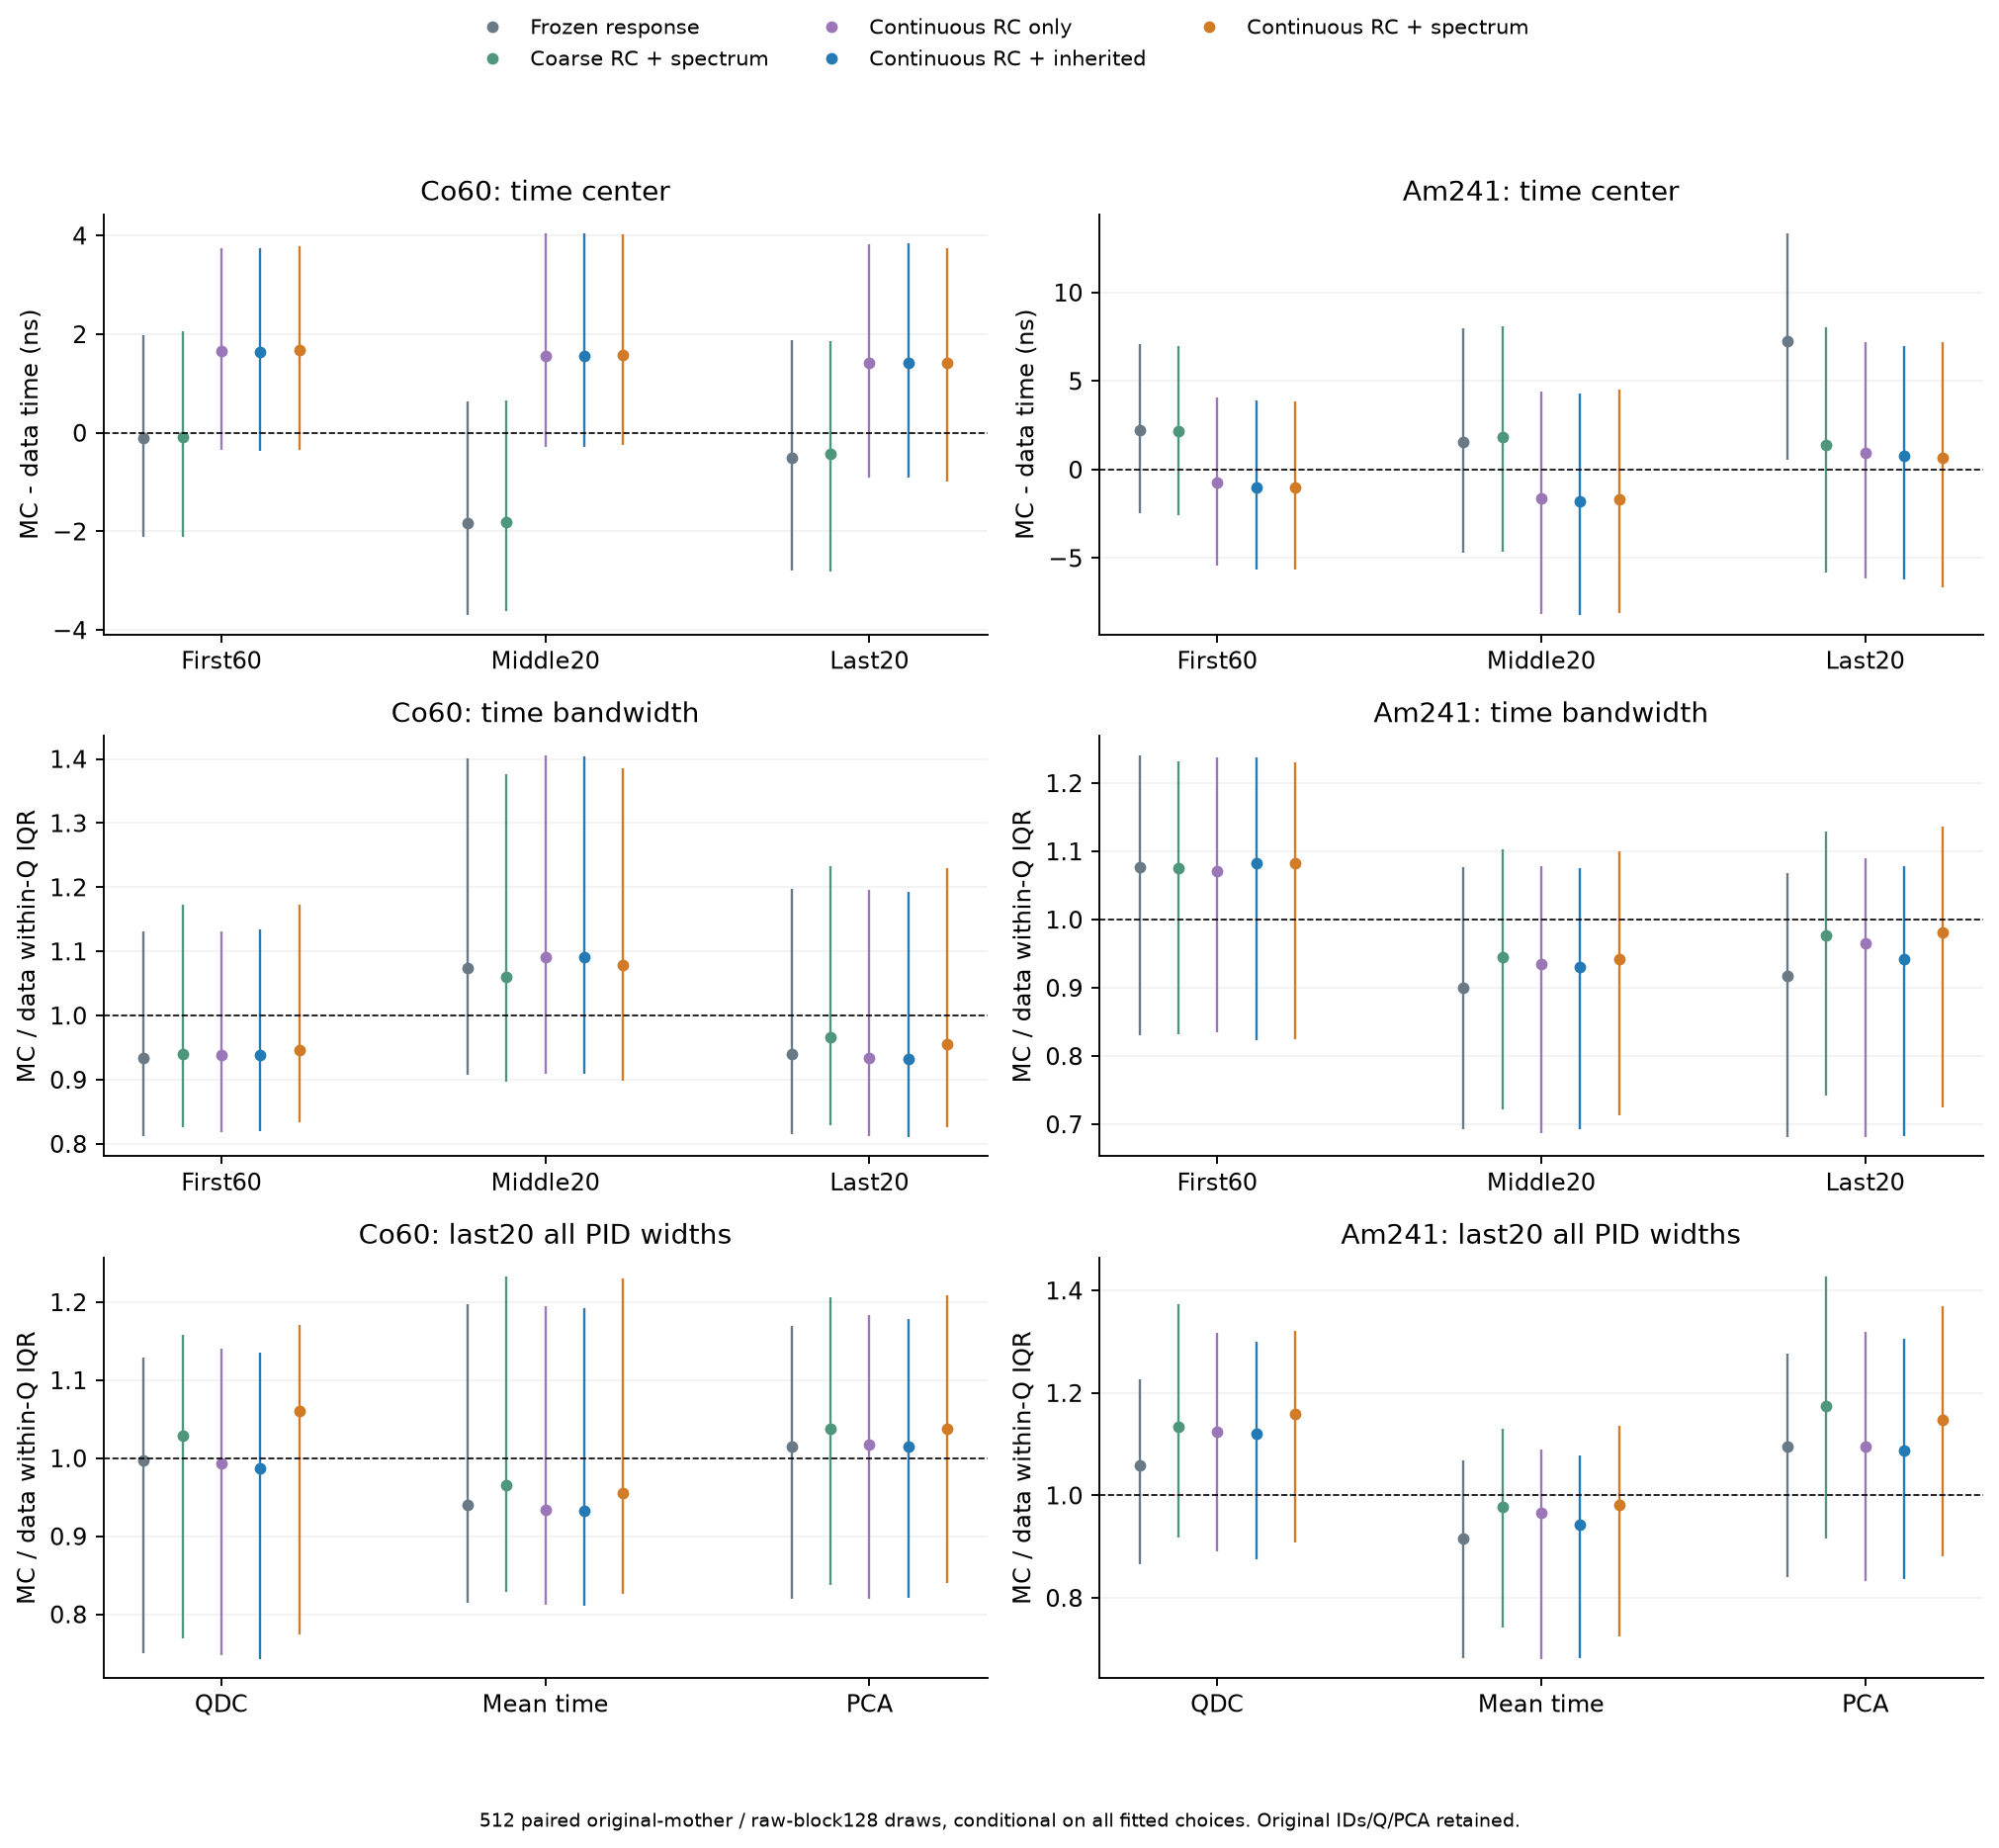

In [5]:
rows=[]
for key,blocks in e['groups'].items():
    for v in ['frozen','coarse_spectrum','mean_only','inherited_CV_fit','spectrum_CV_fit']:
        r=blocks['128']['variants'][v]['point']
        rows.append([key,labels[variants.index(v)],f(r['mean_time_delta_ns']),nums([r[n] for n in ['IQR_ratio_ratio','IQR_time_ratio','IQR_PCA_ratio']]),nums([r[n] for n in ['SD_ratio_ratio','SD_time_ratio','SD_PCA_ratio']]),f(100*r['mean_ADC_NRMSE'],2)+'%'])
display(Markdown(table(['组','模型','时间差/ns','QDC/时间/PCA IQR比','QDC/时间/PCA SD比','ADC NRMSE'],rows)))
display(Image(filename=str(OUT/'figures/refined_joint_checks.png')))

In [6]:
rows=[]
for B in ['128','64']:
    for v,label in zip(variants,labels):
        r=e['groups']['run12_last20'][B]['variants'][v]
        rows.append([B,label,f(r['point']['mean_time_delta_ns']),ci(r['CI95']['mean_time_delta_ns']),f(r['point']['IQR_time_ratio']),ci(r['CI95']['IQR_time_ratio'])])
display(Markdown(table(['块长','Am晚段模型','时间差/ns','条件95%区间/ns','时间IQR比','条件95%区间'],rows)))
display(Markdown(decision['block_stability_zh']))

|块长|Am晚段模型|时间差/ns|条件95%区间/ns|时间IQR比|条件95%区间|
|---|---|---|---|---|---|
|128|原冻结参数|7.258|[0.561, 13.332]|0.917|[0.682, 1.068]|
|128|粗RC+扩展谱|1.407|[-5.796, 8.016]|0.978|[0.742, 1.129]|
|128|连续RC/继承噪声|0.945|[-6.138, 7.203]|0.965|[0.681, 1.090]|
|128|连续RC+原谱/原CV|0.931|[-6.070, 7.096]|0.940|[0.678, 1.074]|
|128|连续RC+原谱/拟合CV|0.795|[-6.180, 6.978]|0.942|[0.683, 1.079]|
|128|连续RC+扩展谱/原CV|0.825|[-6.445, 7.317]|0.985|[0.724, 1.126]|
|128|连续RC+扩展谱/拟合CV|0.678|[-6.644, 7.181]|0.981|[0.725, 1.136]|
|64|原冻结参数|7.258|[0.492, 14.078]|0.917|[0.709, 1.106]|
|64|粗RC+扩展谱|-2.993|[-9.992, 3.887]|0.982|[0.729, 1.170]|
|64|连续RC/继承噪声|1.097|[-6.133, 8.156]|0.922|[0.703, 1.147]|
|64|连续RC+原谱/原CV|1.176|[-5.958, 8.201]|0.898|[0.704, 1.133]|
|64|连续RC+原谱/拟合CV|0.986|[-6.232, 8.081]|0.926|[0.710, 1.135]|
|64|连续RC+扩展谱/原CV|1.892|[-5.136, 8.938]|0.954|[0.759, 1.192]|
|64|连续RC+扩展谱/拟合CV|1.692|[-5.415, 8.717]|0.987|[0.756, 1.196]|

Am晚段块64/128的时间中心差距由粗RC扩展谱的4.40 ns缩小为连续RC扩展谱的1.01 ns；仅更新均值响应时为0.15 ns。新扩展谱的块64/128中心分别为1.69/0.68 ns。这些是内部点估计的稳定性比较，不能把全部变化唯一归因于网格离散，也不能据此识别电路真实RC或温漂。

In [7]:
rows=[]
for source,run in [('Co60',3),('Am241',12)]:
    for v,label in zip(variants,labels):
        r=e['groups'][f'run{run}_last20']['128']['variants'][v]['point']
        rows.append([source,label,nums([r[n] for n in ['F50_ratio','F102_ratio','F202_ratio']]),nums([r[n] for n in ['F50_SD_ratio','F102_SD_ratio','F202_SD_ratio']]),f(r['covariance_normalized_RMSE'])])
display(Markdown(table(['晚段源','模型','F均值比50/102/202','F标准差比50/102/202','归一化协方差RMSE'],rows)))
rows=[]
for source,run in [('Co60',3),('Am241',12)]:
    for v in ['inherited_CV_fit','spectrum_CV_fit']:
        r=e['groups'][f'run{run}_last20']['128']['variants'][v]
        rows.append([source,v,r['control_comparator'],ci(r['paired_from_control']['IQR_time_ratio']),ci(r['paired_from_control']['covariance_normalized_RMSE'])])
display(Markdown(table(['源','CV选择','同谱对照','时间IQR比配对变化区间','协方差误差配对变化区间'],rows)))

|晚段源|模型|F均值比50/102/202|F标准差比50/102/202|归一化协方差RMSE|
|---|---|---|---|---|
|Co60|原冻结参数|1.034 / 1.034 / 1.007|0.989 / 1.141 / 1.231|0.052|
|Co60|粗RC+扩展谱|1.007 / 1.011 / 0.994|0.972 / 1.119 / 1.219|0.031|
|Co60|连续RC/继承噪声|1.034 / 1.031 / 1.000|0.990 / 1.139 / 1.224|0.055|
|Co60|连续RC+原谱/原CV|1.018 / 1.016 / 0.988|0.980 / 1.125 / 1.211|0.058|
|Co60|连续RC+原谱/拟合CV|1.018 / 1.016 / 0.988|0.980 / 1.125 / 1.211|0.058|
|Co60|连续RC+扩展谱/原CV|1.010 / 1.012 / 0.990|0.976 / 1.123 / 1.213|0.030|
|Co60|连续RC+扩展谱/拟合CV|1.010 / 1.012 / 0.990|0.976 / 1.123 / 1.213|0.030|
|Am241|原冻结参数|1.049 / 1.012 / 0.996|1.045 / 1.074 / 0.983|0.174|
|Am241|粗RC+扩展谱|0.999 / 0.984 / 0.989|1.139 / 1.192 / 1.165|0.138|
|Am241|连续RC/继承噪声|1.049 / 1.029 / 1.026|1.169 / 1.236 / 1.201|0.114|
|Am241|连续RC+原谱/原CV|1.017 / 0.998 / 0.997|1.158 / 1.210 / 1.169|0.123|
|Am241|连续RC+原谱/拟合CV|1.028 / 1.009 / 1.007|1.111 / 1.161 / 1.130|0.119|
|Am241|连续RC+扩展谱/原CV|1.001 / 0.985 / 0.990|1.140 / 1.198 / 1.166|0.101|
|Am241|连续RC+扩展谱/拟合CV|1.012 / 0.995 / 0.999|1.090 / 1.150 / 1.126|0.102|

|源|CV选择|同谱对照|时间IQR比配对变化区间|协方差误差配对变化区间|
|---|---|---|---|---|
|Co60|inherited_CV_fit|inherited_CV_fixed|[0.000, 0.000]|[0.000, 0.000]|
|Co60|spectrum_CV_fit|spectrum_CV_fixed|[0.000, 0.000]|[0.000, 0.000]|
|Am241|inherited_CV_fit|inherited_CV_fixed|[-0.009, 0.018]|[-0.012, 0.010]|
|Am241|spectrum_CV_fit|spectrum_CV_fixed|[-0.010, 0.028]|[-0.011, 0.016]|

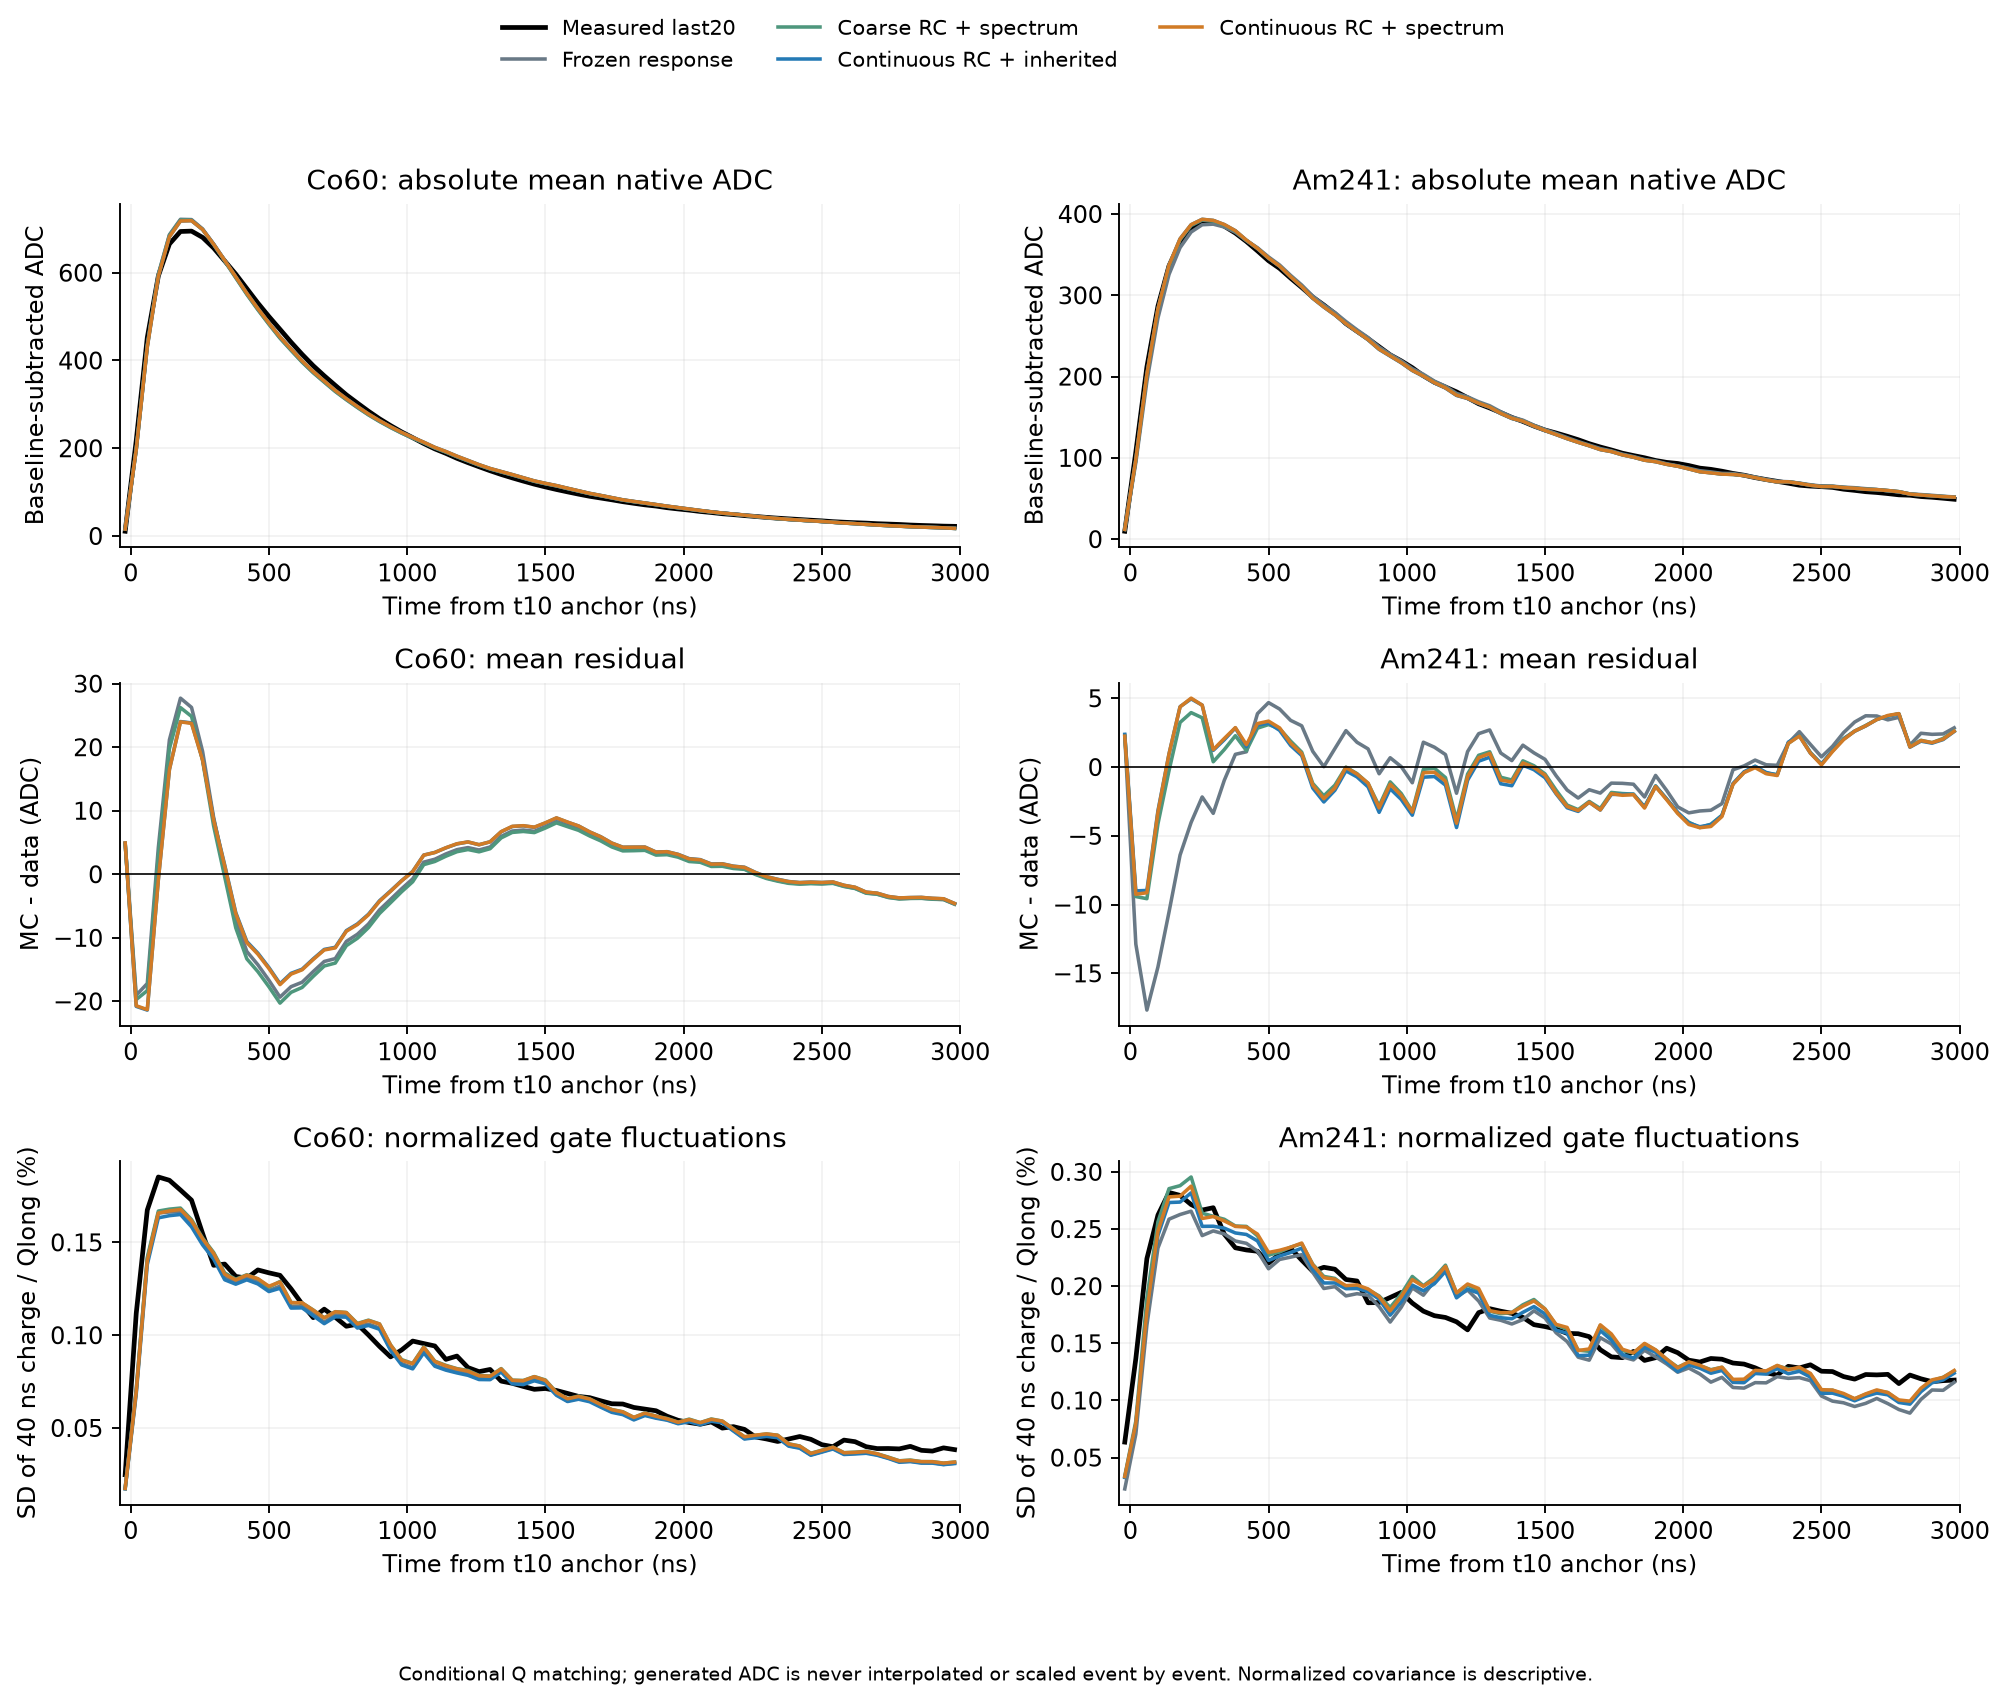

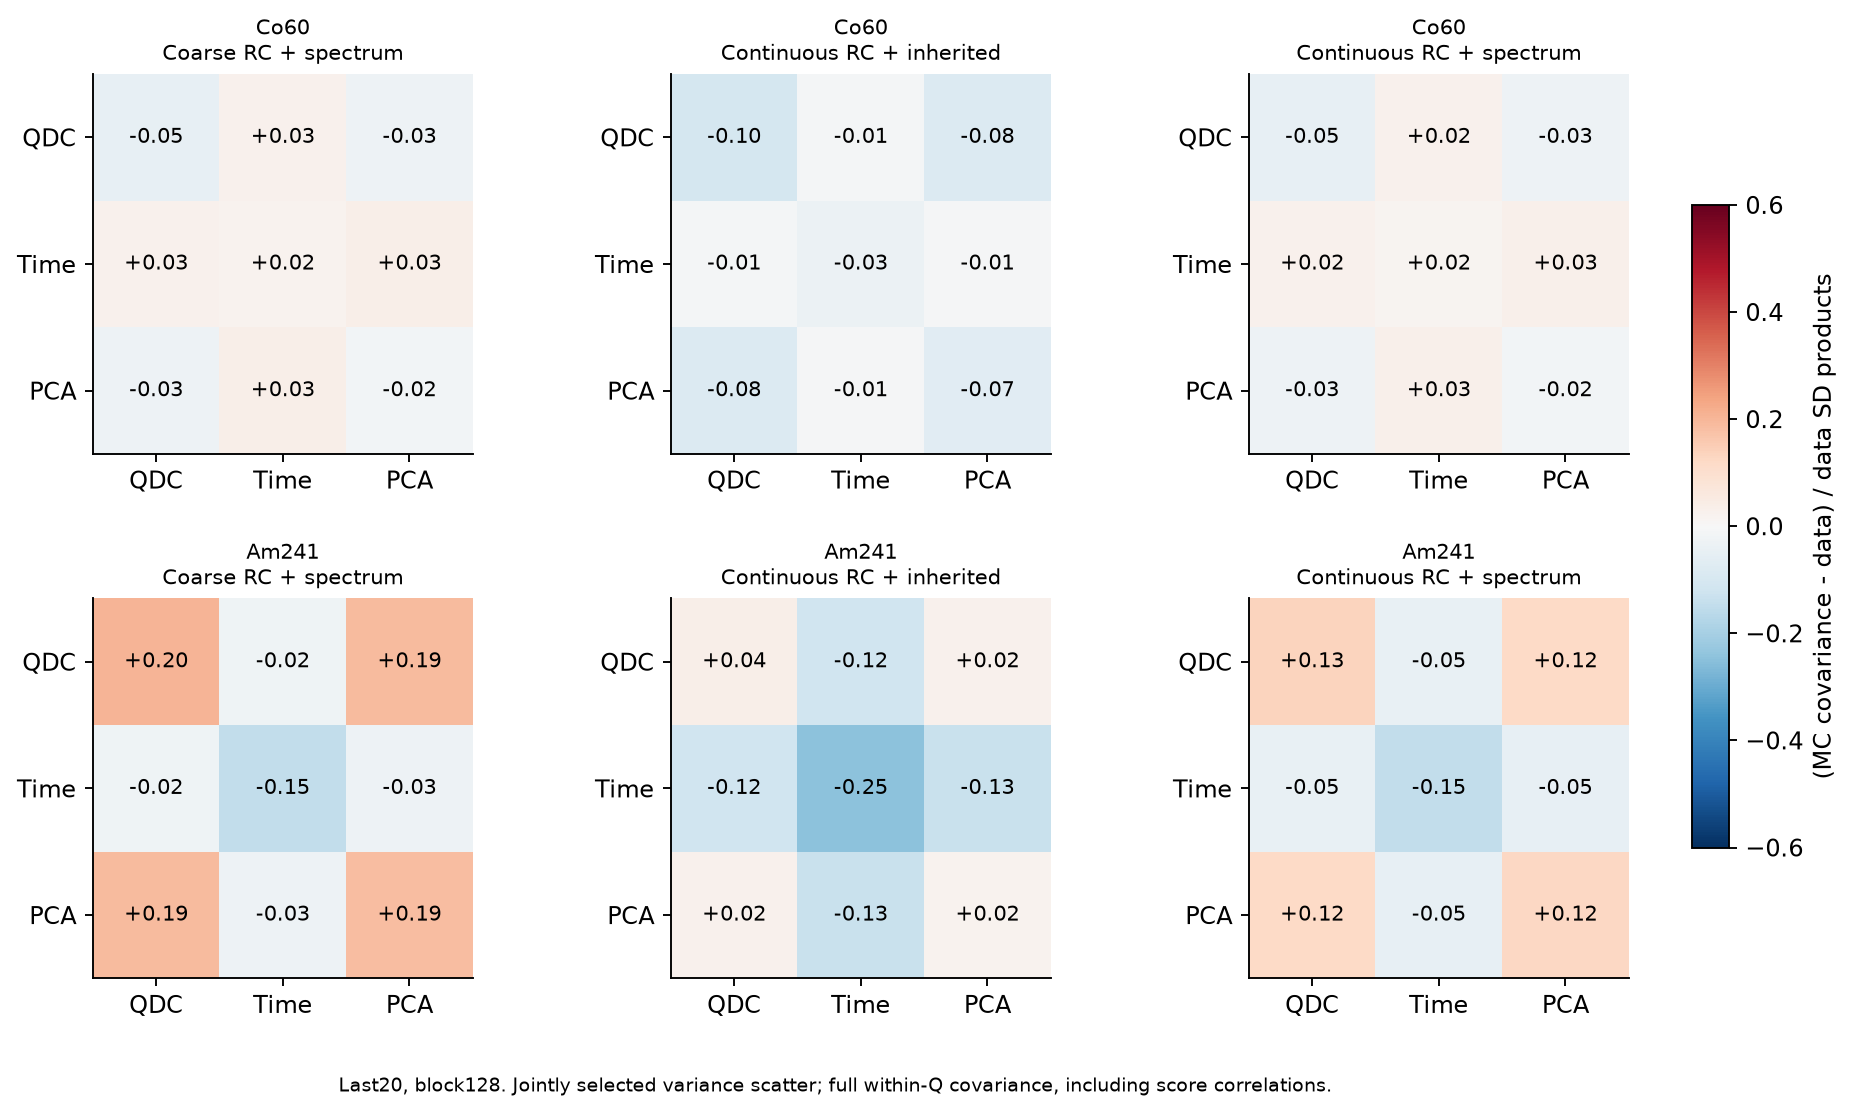

In [8]:
display(Image(filename=str(OUT/'figures/refined_native_waveforms.png')))
display(Image(filename=str(OUT/'figures/refined_PID_covariance.png')))

40 ns电荷份额经每事件Q归一化，总和1；协方差含归一化影响，不直接等于CsI本征波动。
评价折间/折内的协方差恒等式仍保留，折间项含有限样本均值噪声，不等于物理漂移。原CV和拟合CV的对照使用相同RC/功率/谱，配对区间从同一重采样中计算。

## 5. 结论、下一步和复现


In [9]:
display(Markdown(decision['conclusion_zh']))
for finding in decision['findings_zh']:display(Markdown(finding))
display(Markdown(decision['next_work_zh']))
print('默认配置已替换:',decision['promoted_to_default'],'；新增独立母事件:',decision['new_independent_mothers'])
print('复现: rc_refinement_common.py → calibrate_refined_rc.py → verify_rc_cache.py → fit_refined_noise.py → evaluate_refined_rc.py')
print('记录: plot_refined_rc.py → summarize_refined_rc.py → jupyter/codex_0001_build_refined_rc_notebook.py')
print('核验与归档: verify_refined_rc.py；随后 --archive')
print('完整结果:',OUT)

默认配置已替换: False ；新增独立母事件: 0
复现: rc_refinement_common.py → calibrate_refined_rc.py → verify_rc_cache.py → fit_refined_noise.py → evaluate_refined_rc.py
记录: plot_refined_rc.py → summarize_refined_rc.py → jupyter/codex_0001_build_refined_rc_notebook.py
核验与归档: verify_refined_rc.py；随后 --archive
完整结果: /media/sf_works/SiPM/simulation/results/rc_refinement_20261030


本轮完成连续RC、原生含噪声响应校正和噪声分布联合约束。Am晚段扩展谱方案（块128）的MC−实测平均时间差由上一轮1.41 ns变为0.68 ns；时间IQR比为0.981，QDC/PCA IQR比为1.160/1.148，绝对平均ADC波形NRMSE为1.40%。主要进展是时间中心对分块的敏感性减小；三个PID的联合分布仍未全面吻合，不能称为已解决带宽差异。

Am晚段平均时间差的固定拟合条件95%区间为[-6.64, 7.18] ns。时间IQR比相对粗RC的配对变化区间为[-0.069, 0.078]，包含0；不能声称带宽有统计上明确的改善或达到等效。

Am晚段完整PID协方差归一化误差点估计从0.138变为0.102，但配对变化区间包含0。QDC/PCA的核心宽度仍偏大；三项F的事件间SD比为1.09/1.15/1.13。

在本轮两个谱族、固定功率拟合和48个条件/谱族组合中，Co全部24项保留原CV；Am19项选择CV=0、5项保留原小CV。较大的事件方差CV均未被训练目标选中。因此本谱族内继续增加这类噪声波动缺乏支持；这不排除其它波形相关机制。

Co晚段扩展谱的时间差从-0.44变为1.41 ns，绝对均ADC NRMSE从3.18%变为2.96%。中心更接近零这一点没有改善，多目标拟合存在权衡，不能只报告Am的改善。

原生缓存是计算优化，216个配对事件对照中ADC、无噪声信号和模拟电压逐点等于旧程序。研究重放反复使用470个原母事件（支持Q箱内456个），重复条目不增加独立MC统计。

下一步固定本轮校准，不再按单一带宽追加全局噪声。先在原Q箱内比较三个PID的中心核心、尾部概率和相关方向，关联F50/102/202、前触发状态与40 ns波形残差；实测分组规则只从训练块确定，保留原事件全集，尾部检查仅用于诊断。利用现有Geant4祖先标签核查源混合/能损拓扑对模拟尾部的贡献，但不把Am实验主带标成纯α。只有形成同时约束均波形、IQR、完整协方差和起伏分布的稳定候选后，才冻结参数并运行新种子Geant4母事件；已有实验始终作为内部条件检查。

`protocol.json`在新数值之前冻结方案，准备代码存于`source_snapshot/rc_refinement_common_frozen.py`。随后采用的原生缓存只优化计算，其采用前核验见`cache_verification.json`。
`fits/`保存训练ID、连续拟合、全部CV和条件重拟合；`native/`是原生ROOT，`arrays/`含ADC及提取；配对抽样保存在`evaluation_bootstrap.npz`。最终`verification.json`和`record.json`记录独立核验及输入/输出/源码哈希。
新研究不得覆盖当前结果。共享文献库未修改；本轮未联网、下载论文或进行新实验。
